# Calibrating the reference curve

The interaction map measures a protein against a reference: what a chain with no
interactions of its own would do. That reference is a power law

$$p_{\mathrm{ref}}(s) = a \cdot s^{\,b}$$

in the sequence separation $s = j - i$, fitted on glycine-serine linkers, which are
taken to behave as that interaction-free chain.

This notebook fits it. The fitting lives in `interaction_map.util.calibrate`, which is
deliberately independent of the analysis: it takes a cutoff and a scheme as arguments
rather than reading them from a profile, because its job is to produce the numbers a
profile is later given, and a calibration that inherited the constants it is meant to
measure would be worth nothing.


## What you need

Reference trajectories. The published constants were fitted on GS linkers of 8 to 32
repeats.

The example below runs on the small coarse-grained fixture in the repository, so the
notebook executes with no external data. **That fixture is a p53 mutant, not a linker**,
so the numbers it produces are not a reference curve. They show the machinery working,
nothing more.


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from interaction_map.util import calibrate as cal

FIXTURES = os.path.join('..', 'tests', 'fixtures')
PDB = os.path.join(FIXTURES, 'A39G_K24Y.pdb')
DCD = os.path.join(FIXTURES, 'A39G_K24Y.dcd')


## Fit

`all_pairs=True` with `scheme='closest-heavy'` is what a one-bead-per-residue model
needs: its beads are not named `CA`, so asking for the `ca` scheme finds nothing at all.
For an all-atom trajectory use the defaults, `scheme='ca'` and `all_pairs=False`.


In [2]:
fit = cal.calibrate(PDB, DCD,
                    cutoff=1.2,
                    scheme='closest-heavy',
                    all_pairs=True,
                    source='CG fixture, not a linker: demonstration only')

print(cal.summarise(fit))


p_ref(s) = 13.33 * s ** -2.339
  standard error      a 0.683, b 0.0406
  R squared           0.99352
  fitted over         separation 3 to 60, 58 points
  cutoff              1.2 nm, scheme 'closest-heavy'
  from                1000 frames, 61 residues, 1 trajectory file(s)
  WARNING             returns a value above 1 at separation 3 and below, where it cannot be a probability
  largest residual    +0.07715 at separation 4


## Look at the fit, do not just take the numbers

A power law will fit almost anything over a short range. Plot it on log axes, where a
power law is a straight line, and watch where the measured points leave it.


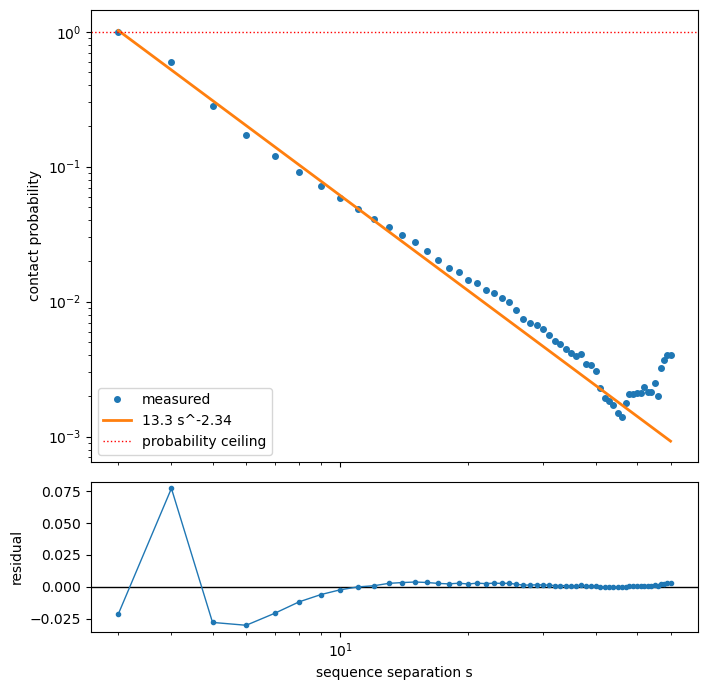

In [3]:
separations = np.array(fit['separations'])
observed = np.array(fit['observed'])
predicted = np.array(fit['predicted'])

figure, (upper, lower) = plt.subplots(2, 1, figsize=(7, 7), sharex=True,
                                      gridspec_kw={'height_ratios': [3, 1]})

upper.plot(separations, observed, 'o', ms=4, label='measured')
upper.plot(separations, predicted, '-', lw=2,
           label='%.3g s^%.3g' % (fit['a'], fit['b']))
upper.axhline(1.0, color='red', ls=':', lw=1, label='probability ceiling')
upper.set_xscale('log')
upper.set_yscale('log')
upper.set_ylabel('contact probability')
upper.legend()

lower.axhline(0, color='black', lw=1)
lower.plot(separations, np.array(fit['residuals']), 'o-', ms=3, lw=1)
lower.set_xlabel('sequence separation s')
lower.set_ylabel('residual')

figure.tight_layout()


## Where the curve stops being a probability

A power law with a negative exponent climbs without limit as $s$ falls, so below some
separation it returns a value above 1. No contact probability can exceed 1, and a pair
there is scored as strongly repulsive whatever it actually does.

This is not hypothetical. It is why every bonded neighbour in a coarse-grained map comes
out at the strongest repulsive level, and why `min_sep` keeps them out of the figure.


In [4]:
ceiling = cal.probability_ceiling(fit)
print('p_ref exceeds 1 at separation', ceiling, 'and below')
for s in range(1, 7):
    value = cal.power_law(s, fit['a'], fit['b'])
    flag = '   <-- impossible as a probability' if value > 1 else ''
    print('  s={0}: p_ref = {1:8.4f}{2}'.format(s, value, flag))


p_ref exceeds 1 at separation 3 and below
  s=1: p_ref =  13.3341   <-- impossible as a probability
  s=2: p_ref =   2.6356   <-- impossible as a probability
  s=3: p_ref =   1.0210   <-- impossible as a probability
  s=4: p_ref =   0.5210
  s=5: p_ref =   0.3091
  s=6: p_ref =   0.2018


## Save it with its provenance

The fit is stored with the cutoff, the scheme, the separation range it covers, the
trajectories it came from and the time it was made.

The cutoff matters most. The curve describes contacts *at that cutoff* and says nothing
about any other, so a reference used at the wrong cutoff is simply wrong.


In [5]:
path = cal.save(fit, 'reference_fixture.json')

reloaded = cal.load(path)
for key in ['a', 'b', 'cutoff', 'scheme', 'separation_min', 'separation_max',
            'n_frames', 'n_trajectories', 'source', 'fitted']:
    print('{0:18} {1}'.format(key, reloaded[key]))


a                  13.33407751664377
b                  -2.3389068698242124
cutoff             1.2
scheme             closest-heavy
separation_min     3
separation_max     60
n_frames           1000
n_trajectories     1
source             CG fixture, not a linker: demonstration only
fitted             2026-10-26T03:49:42Z


## Doing it for real

On GS linkers, from the command line, with several repeats:

```
python -m interaction_map.util.calibrate \
    GS16-summary/BB/S_0/__START_0.pdb \
    GS16-summary/BB/S_0/__traj_*.xtc \
    --cutoff 0.8 --sep 3 60 \
    --source 'GS16, 5 repeats' --out references/gs16.json
```

Two things to settle before trusting the result.

**The cutoff must be the one the analysis will use** — 0.8 nm for all-atom, 1.2 nm for
CALVADOS. A curve fitted at one cutoff does not describe another.

**The separation range must cover the proteins you intend to study.** Beyond the fitted
range the curve is an extrapolation, and a long-range interaction judged against an
extrapolated reference is not a measurement.


## A note on the constants currently shipped

`profiles.ALL_ATOM` carries $a = 1.64$, $b = -1.33$ and `profiles.CG` carries
$a = 13.12$, $b = -2.32$. Neither traces to a recorded fit in this repository.

The GS notebooks this module was taken from fit GS16 alone and report $a = 2.175$,
$b = -1.555$ for all-atom at a 0.8 nm cutoff, which is not what is shipped. The
published Methods describe linkers of 8 to 32 repeats, so the shipped values presumably
came from the pooled set rather than from GS16 alone.

Until that is re-derived and saved, the constants are inherited rather than verified.
Running this notebook on the full GS set is what would close the gap.
